# Volcano: shallow forcing or deeper edifice change?

**Question.** Is a negative $dv/v(f)$ associated with shallow environmental forcing, a deeper elastic change, or a mixture you cannot resolve?

Use a **synthetic basaltic-edifice column**: 0–300 m of low-speed material, 300–1500 m of more competent rock, and a faster substrate. These values are chosen for teaching, not a calibrated model of Piton de la Fournaise. The 0.5–1.8 Hz band samples overlapping parts of the edifice. The model is flat, isotropic, elastic, and laterally uniform.

[Brenguier et al. (2008)](https://doi.org/10.1038/ngeo104) motivate monitoring small volcanic velocity changes. Our notebook does not reproduce their measurements or establish an eruption precursor. The current GESC operator uses direct fundamental phase changes; their coda-monitoring interpretation cannot be transferred without an estimator-specific sensitivity model.


In [1]:
import sys
from pathlib import Path

# Run from the repository root or its tutorials/ directory.
root = Path.cwd().resolve()
if root.name == "tutorials":
    root = root.parent
if not (root / "src" / "gesc").is_dir():
    raise RuntimeError("Run this notebook from the gesc-python checkout.")
sys.path.insert(0, str(root))
sys.path.insert(0, str(root / "src"))
import matplotlib.pyplot as plt
import numpy as np

from gesc import solve_modes
from gesc.inversion import LinearInverseRequest, infer_time_lapse
from gesc.sensitivity import linearize_phase, perturb_model
from tutorials.plotting import emit_metrics, model_table, report_figure, sensitivity_figure, style
from tutorials.scenarios import correlated_covariance, phase_observation, select_band

style()
np.set_printoptions(precision=5, suppress=True)
%matplotlib inline

Depth (m),Vp (m/s),Vs (m/s),Density (kg/m³)
0–300,2000.0,900.0,2000.0
300–1500,3600.0,1800.0,2400.0
1500–∞,5000.0,2800.0,2700.0


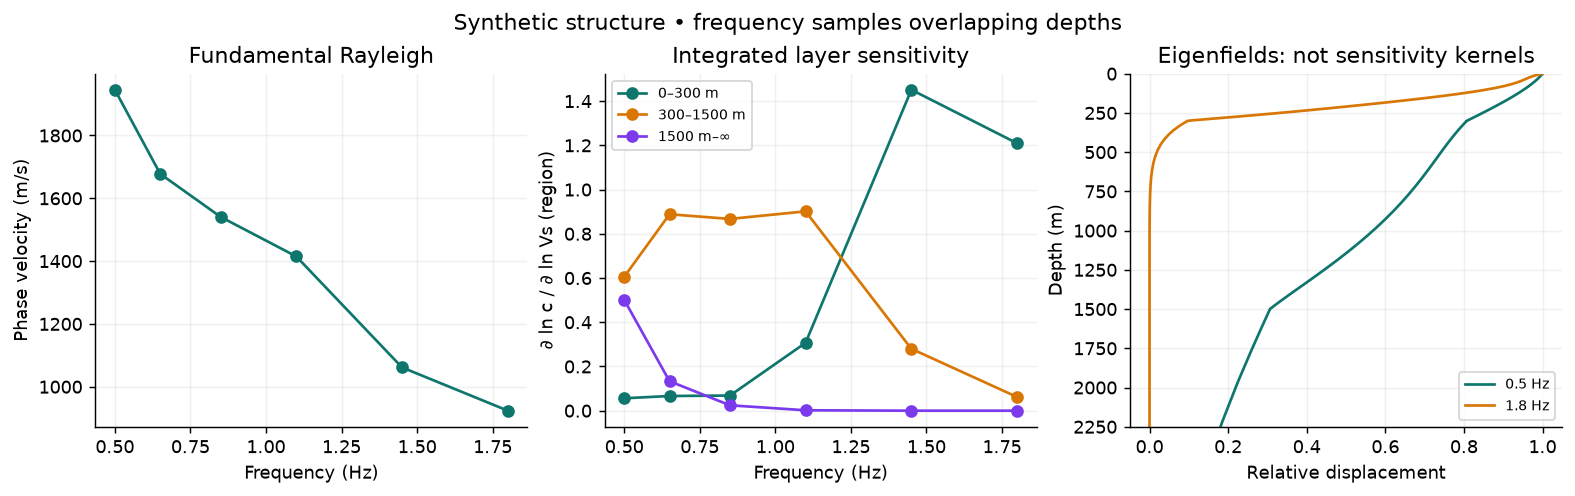

In [2]:
from tutorials.scenarios import volcano

model, request = volcano()
observation = phase_observation(request)
model_table(model)
modes = solve_modes(model, request).fundamental()
operator = linearize_phase(model, request, observation)
G = np.array(operator.g)
f = np.array(request.frequencies_hz)
sensitivity_figure(modes, operator)

## 1. Compare hypotheses in data space

Give a shallow change and a deeper change the same maximum regional amplitude. Their frequency signatures are predictions of this background, not universal volcano fingerprints. A hydrothermal zone may be shallower or deeper at your volcano; an edifice-scale strain field need not be confined to one layer.


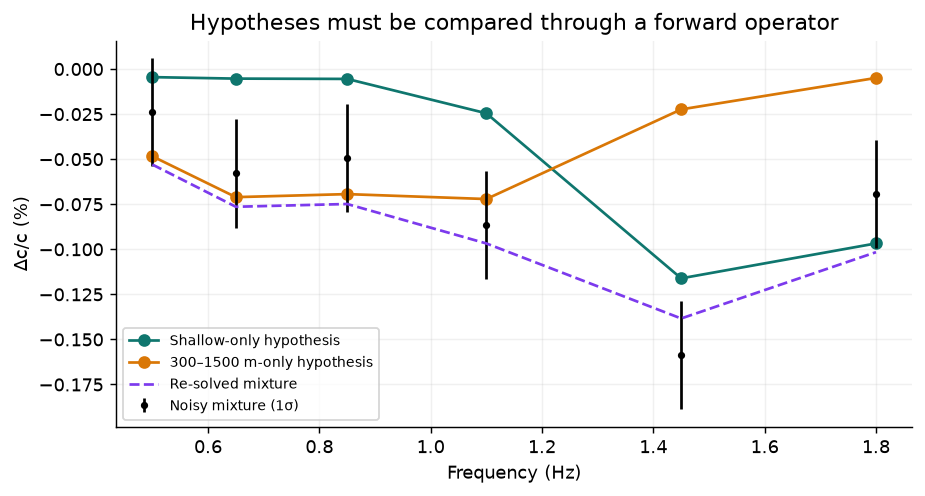

In [3]:
shallow = np.array([-8e-4, 0, 0])
deep = np.array([0, -8e-4, 0])
truth = shallow + deep
Cd = correlated_covariance(len(f), sigma=3e-4, correlation=0.5)
changed = solve_modes(perturb_model(model, truth), request).fundamental()
c0 = np.array([m.phase_velocity_m_s for m in modes])
resolved = np.array([m.phase_velocity_m_s for m in changed]) / c0 - 1
linear_error = float(np.max(np.abs(resolved - operator.predict(truth))))
assert linear_error < 0.25 * 3e-4
rng = np.random.default_rng(1029)
data = resolved + rng.multivariate_normal(np.zeros(len(f)), Cd)
fig, ax = plt.subplots(figsize=(7, 3.7))
ax.plot(f, operator.predict(shallow) * 100, "o-", label="Shallow-only hypothesis")
ax.plot(f, operator.predict(deep) * 100, "o-", label="300–1500 m-only hypothesis")
ax.errorbar(f, data * 100, yerr=np.sqrt(np.diag(Cd)) * 100, fmt="k.", label="Noisy mixture (1σ)")
ax.plot(f, resolved * 100, "--", label="Re-solved mixture")
ax.set(
    xlabel="Frequency (Hz)",
    ylabel="Δc/c (%)",
    title="Hypotheses must be compared through a forward operator",
)
ax.legend(fontsize=8)
plt.show()

## 2. Joint depth inference

Estimate all three regional $\Delta\ln V_s$ coefficients with a 0.2% prior standard deviation. The halfspace coefficient represents all depths below 1.5 km and cannot locate a reservoir at a particular depth. Read the posterior correlations and averaging matrix before assigning the change to a structural unit.


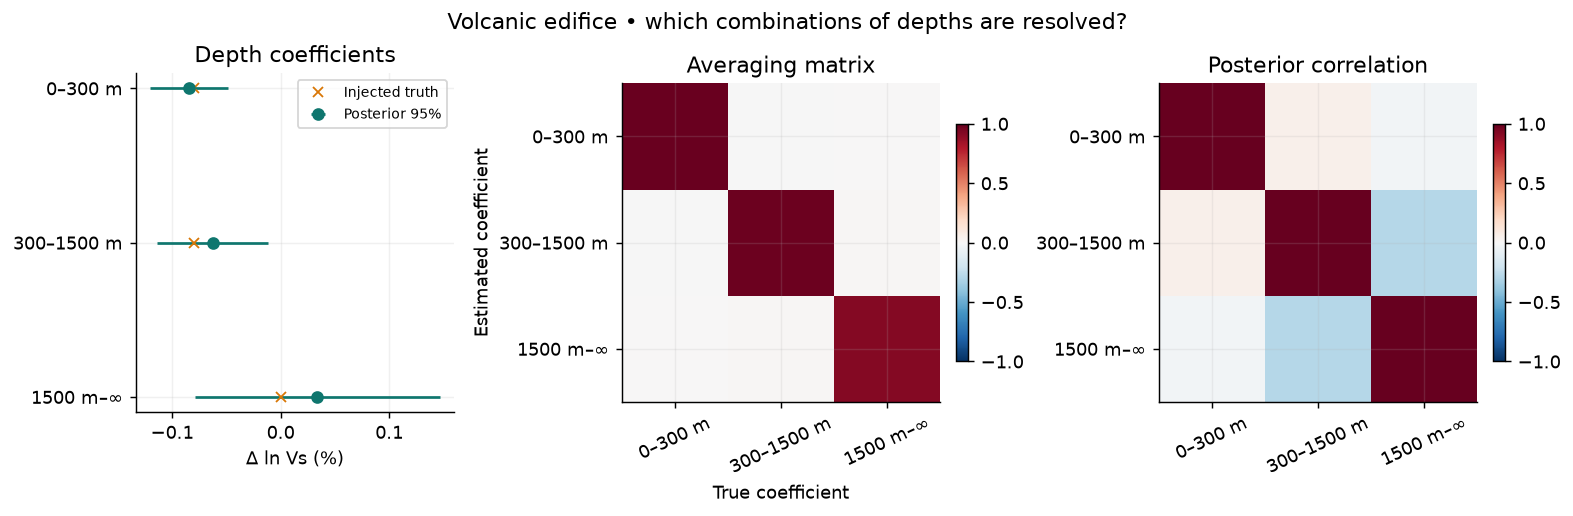

Prior-dominated: (False, False, False)
Whitened singular values: (10.894598728760096, 7.953836029140916, 3.290553306097764)
Residuals divided by marginal σ: [ 0.0584  -0.03885  0.32798 -0.14247 -0.62491  1.22351]


In [4]:
Ca = np.eye(3) * 0.002**2
report = infer_time_lapse(
    operator,
    LinearInverseRequest(
        data_fractional=tuple(data),
        data_covariance=tuple(map(tuple, Cd)),
        prior_mean=(0, 0, 0),
        prior_covariance=tuple(map(tuple, Ca)),
    ),
)
report_figure(
    operator, truth, report, "Volcanic edifice • which combinations of depths are resolved?"
)
print("Prior-dominated:", report.prior_dominated)
print("Whitened singular values:", report.whitened_singular_values)
print(
    "Residuals divided by marginal σ:", np.array(report.residual_fractional) / np.sqrt(np.diag(Cd))
)

## 3. Frequency coverage and background dependence

Keep only 1.1–1.8 Hz and recompute the posterior. Removing low frequencies cannot improve information under the same model and covariance. For a real edifice, repeat the experiment across plausible background models, with topography and lateral heterogeneity considered separately; a single-column Gaussian posterior does not include those uncertainties.


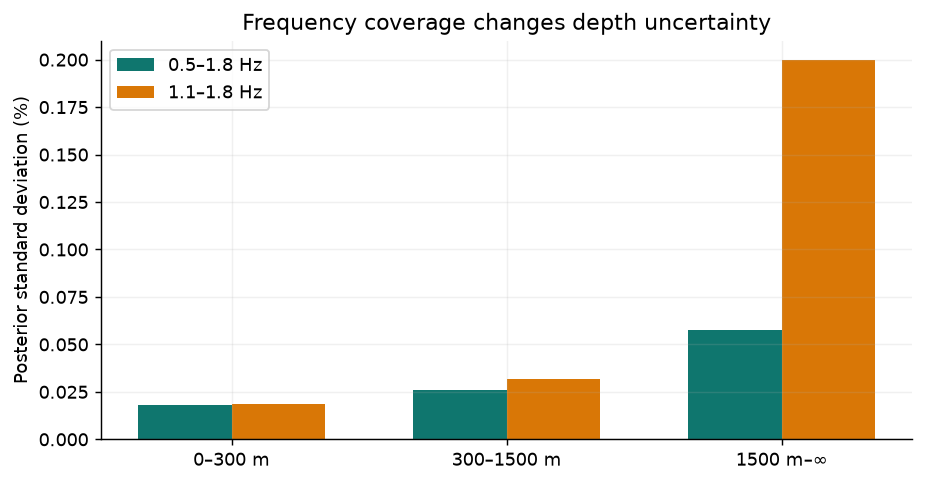

In [5]:
keep = np.array([3, 4, 5])
high_report = infer_time_lapse(
    select_band(operator, keep),
    LinearInverseRequest(
        data_fractional=tuple(data[keep]),
        data_covariance=tuple(map(tuple, Cd[np.ix_(keep, keep)])),
        prior_mean=(0, 0, 0),
        prior_covariance=tuple(map(tuple, Ca)),
    ),
)
all_sd = np.sqrt(np.diag(report.covariance_log_vs))
high_sd = np.sqrt(np.diag(high_report.covariance_log_vs))
assert np.all(all_sd <= high_sd + 1e-10)
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(3)
ax.bar(x - 0.17, all_sd * 100, width=0.34, label="0.5–1.8 Hz")
ax.bar(x + 0.17, high_sd * 100, width=0.34, label="1.1–1.8 Hz")
ax.set(
    xticks=x,
    xticklabels=("0–300 m", "300–1500 m", "1500 m–∞"),
    ylabel="Posterior standard deviation (%)",
    title="Frequency coverage changes depth uncertainty",
)
ax.legend()
plt.show()

## Interpretation for a monitoring team

A negative elastic perturbation is consistent with several mechanisms: changes in effective stress, crack compliance, temperature, fluid state, or damage. To distinguish them, compare seismic changes with rainfall, groundwater, deformation, gas, thermal observations, and source/wavefield stability. The tests here demonstrate a forward/inverse elastic calculation; they do not calibrate pressure, locate magma, or predict an eruption.

**Try:** impose a change below 1.5 km; compare its fitted shallow leakage. Change the prior width. Add a weather-related shallow term to a deeper event. If the averaging rows overlap strongly, describe a resolved combination rather than a sharply located source.


In [6]:
emit_metrics(
    {
        "case": "synthetic volcanic edifice",
        "frequencies_hz": list(f),
        "max_numerical_phase_error": max(operator.numerical_phase_error_estimate),
        "max_linearization_discrepancy": linear_error,
        "posterior_mean_log_vs": list(report.mean_log_vs),
        "posterior_sd_log_vs": all_sd.tolist(),
        "prior_dominated": list(report.prior_dominated),
        "checks_passed": True,
    }
)

{
  "case": "synthetic volcanic edifice",
  "frequencies_hz": [
    0.5,
    0.65,
    0.85,
    1.1,
    1.45,
    1.8
  ],
  "max_numerical_phase_error": 9.262817179944705e-10,
  "max_linearization_discrepancy": 1.2767467747699848e-06,
  "posterior_mean_log_vs": [
    -0.0008434574227341944,
    -0.0006266204237906623,
    0.00033703041431619403
  ],
  "posterior_sd_log_vs": [
    0.00018332954011735485,
    0.00026230771256464377,
    0.0005757045159953606
  ],
  "prior_dominated": [
    false,
    false,
    false
  ],
  "checks_passed": true
}

case,synthetic volcanic edifice
frequencies hz,"[0.5, 0.65, 0.85, 1.1, 1.45, 1.8]"
max numerical phase error,9.262817179944705e-10
max linearization discrepancy,1.2767467747699848e-06
posterior mean log vs,"[-0.0008434574227341944, -0.0006266204237906623, 0.00033703041431619403]"
posterior sd log vs,"[0.00018332954011735485, 0.00026230771256464377, 0.0005757045159953606]"
prior dominated,"[False, False, False]"
checks passed,True
